In [1]:
# Assignment 6: Bias-Variance Tradeoff

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(0)
X = np.sort(np.random.rand(60, 1), axis=0)
y = np.sin(2 * np.pi * X).ravel() + np.random.normal(0, 0.3, 60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

Degree 1: Train error = 0.246, Test error = 0.195
Degree 4: Train error = 0.067, Test error = 0.085
Degree 15: Train error = 0.052, Test error = 0.150


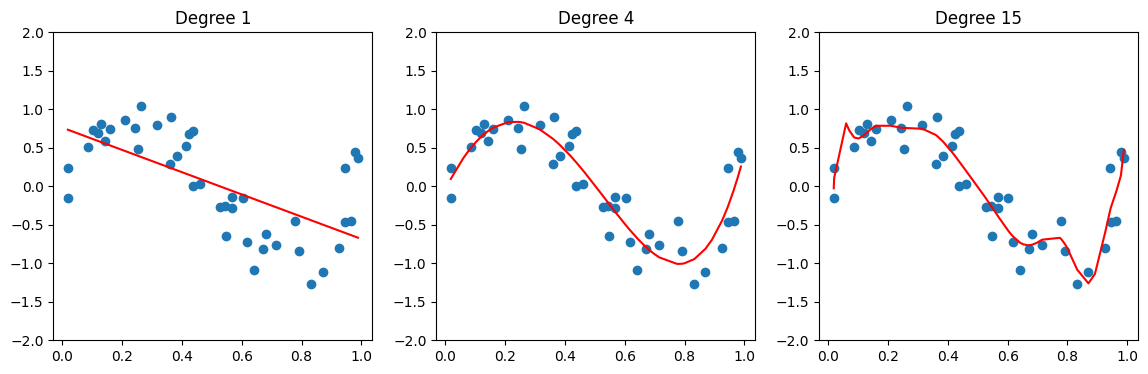

In [2]:
degrees = [1, 4, 15]     # underfit, good fit, overfit
plt.figure(figsize=(14, 4))

for i, d in enumerate(degrees):
    poly = PolynomialFeatures(d)
    model = LinearRegression().fit(poly.fit_transform(X_train), y_train)

    train_err = mean_squared_error(y_train, model.predict(poly.transform(X_train)))
    test_err = mean_squared_error(y_test, model.predict(poly.transform(X_test)))
    print(f"Degree {d}: Train error = {train_err:.3f}, Test error = {test_err:.3f}")

    plt.subplot(1, 3, i + 1)
    plt.scatter(X_train, y_train)
    plt.plot(X, model.predict(poly.transform(X)), color='r')
    plt.ylim(-2, 2)
    plt.title(f"Degree {d}")
plt.show()